# Part 2 Washing-machine exploratory analysis

This notebook uses the official cleaned REFIT files. It loads selected washing-machine channels, converts them to one-minute readings, detects washing-machine cycles, and compares usage across households.


## 1. Configuration and imports

All analysis thresholds are kept in one dictionary. The cycle rule is intentionally simple: power above 20 W means the washer is active; pauses shorter than 10 minutes are merged into the same cycle; cycles shorter than 10 minutes or below 20 Wh are discarded.

In [8]:
# project root directory
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = Path.cwd().resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from eda import (
    availability_summary,
    cycle_usage_tables,
    detect_cycles,
    load_house,
    resample_house,
)

CLEAN_DIR = PROJECT_ROOT / "data" / "cleaned" / "CLEAN_REFIT_081116"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HOUSES = {
    1: "Appliance5",
    2: "Appliance2",
    3: "Appliance6",
    5: "Appliance3",
}

CONFIG = {
    "active_power_watts": 20.0,
    "merge_pause_minutes": 10,
    "minimum_cycle_minutes": 10,
    "minimum_cycle_energy_wh": 20.0,
    "max_gap_minutes": 3,
}

print(f"Cleaned data directory: {CLEAN_DIR}")
print(f"Selected houses: {HOUSES}")
print(f"Configuration: {CONFIG}")

Cleaned data directory: D:\FLOCK_ENERGY_ASSIGNMENT\refit-appliance-disaggregation\data\cleaned\CLEAN_REFIT_081116
Selected houses: {1: 'Appliance5', 2: 'Appliance2', 3: 'Appliance6', 5: 'Appliance3'}
Configuration: {'active_power_watts': 20.0, 'merge_pause_minutes': 10, 'minimum_cycle_minutes': 10, 'minimum_cycle_energy_wh': 20.0, 'max_gap_minutes': 3}


In [9]:
# Load and resample data for each house, then summarize availability.

house_data = {}
availability_rows = []

for house_number, washer_column in HOUSES.items():
    raw = load_house(CLEAN_DIR, house_number, washer_column)
    minute_data, report = resample_house(
        raw,
        washer_column,
        max_gap_minutes=CONFIG["max_gap_minutes"],
    )
    house_data[house_number] = {
        "washer_column": washer_column,
        "data": minute_data,
        "report": report,
    }
    availability_rows.append({"house": house_number, **report})

availability = pd.DataFrame(availability_rows)
display(availability)

,house,start,end,minutes,issue_rows_removed,missing_minutes,short_gap_minutes_filled,max_gap_minutes
0,1,2013-10-09T13:06:00,2015-07-10T11:56:00,920091,58183,118760,1222,3
1,2,2013-09-17T22:08:00,2015-05-28T08:05:00,889078,28444,219151,482,3
2,3,2013-09-25T19:21:00,2015-06-02T10:55:00,885095,408627,132557,3541,3
3,5,2013-09-26T09:56:00,2015-07-06T17:48:00,933593,425766,118449,5211,3


In [10]:
# detect cycles and create summaries for each household

from eda import availability_summary, cycle_usage_tables, detect_cycles

def analyse_house(house_number, house_info):
    """Detect cycles and create summaries for one household."""
    washer_column = house_info["washer_column"]
    minute_data = house_info["data"]

    cycles = detect_cycles(
        minute_data,
        washer_column,
        active_power_watts=CONFIG["active_power_watts"],
        merge_pause_minutes=CONFIG["merge_pause_minutes"],
        minimum_cycle_minutes=CONFIG["minimum_cycle_minutes"],
        minimum_cycle_energy_wh=CONFIG["minimum_cycle_energy_wh"],
    )

    availability_row = {
        "house": house_number,
        "washer_channel": washer_column,
        **availability_summary(
            minute_data,
            washer_column,
            cycles,
            CONFIG["active_power_watts"],
        ),
    }
    hour_table, day_table = cycle_usage_tables(cycles)
    hour_table.insert(0, "house", house_number)
    day_table.insert(0, "house", house_number)
    cycles = cycles.assign(house=house_number)
    return cycles, availability_row, hour_table, day_table


analysis_results = [
    analyse_house(house_number, house_info)
    for house_number, house_info in house_data.items()
]

cycle_tables = {
    house_number: result[0]
    for house_number, result in zip(house_data, analysis_results, strict=True)
}
availability = pd.DataFrame(result[1] for result in analysis_results)
hour_usage = pd.concat(
    [result[2] for result in analysis_results],
    ignore_index=True,
)
day_usage = pd.concat(
    [result[3] for result in analysis_results],
    ignore_index=True,
)
cycles_all = pd.concat(
    [result[0] for result in analysis_results],
    ignore_index=True,
)

display(availability)
display(cycles_all.head())

,house,washer_channel,start,end,total_days,total_minutes,missing_minutes,missing_percent,valid_minutes,off_minutes,off_percent_of_valid,cycle_count
0,1,Appliance5,2013-10-09 13:06:00,2015-07-10 11:56:00,638.951389,920091,118760,12.907419,801331,786972,98.208106,403
1,2,Appliance2,2013-09-17 22:08:00,2015-05-28 08:05:00,617.414583,889078,219151,24.649243,669927,639023,95.386960,341
2,3,Appliance6,2013-09-25 19:21:00,2015-06-02 10:55:00,614.648611,885095,132557,14.976584,752538,711640,94.565324,680
3,5,Appliance3,2013-09-26 09:56:00,2015-07-06 17:48:00,648.327778,933593,118449,12.687434,815144,759567,93.181941,868


,cycle_id,start,end,duration_minutes,energy_wh,peak_power_watts,mean_power_watts,start_hour,start_day,house
0,1,2013-10-23 05:59:00,2013-10-23 07:15:00,77,496.075891,2368.727273,386.552642,5,Wednesday,1
1,3,2013-10-23 13:11:00,2013-10-23 13:36:00,26,54.103846,530.800000,124.855028,13,Wednesday,1
2,5,2013-10-23 14:12:00,2013-10-23 14:39:00,28,63.052500,499.000000,135.112500,14,Wednesday,1
3,7,2013-10-24 10:17:00,2013-10-24 10:42:00,26,50.241212,424.111111,115.941259,10,Thursday,1
4,9,2013-10-26 11:41:00,2013-10-26 12:07:00,27,53.239762,349.857143,118.310582,11,Saturday,1


In [11]:
# summarize and save results to CSV files

availability.to_csv(OUTPUT_DIR / "washer_availability.csv", index=False)
cycles_all.to_csv(OUTPUT_DIR / "washer_cycles.csv", index=False)
hour_usage.to_csv(OUTPUT_DIR / "washer_cycles_by_hour.csv", index=False)
day_usage.to_csv(OUTPUT_DIR / "washer_cycles_by_day.csv", index=False)

print("Saved summary tables:")
for filename in [
    "washer_availability.csv",
    "washer_cycles.csv",
    "washer_cycles_by_hour.csv",
    "washer_cycles_by_day.csv",
]:
    print(f"- {OUTPUT_DIR / filename}")

Saved summary tables:
- D:\FLOCK_ENERGY_ASSIGNMENT\refit-appliance-disaggregation\outputs\washer_availability.csv
- D:\FLOCK_ENERGY_ASSIGNMENT\refit-appliance-disaggregation\outputs\washer_cycles.csv
- D:\FLOCK_ENERGY_ASSIGNMENT\refit-appliance-disaggregation\outputs\washer_cycles_by_hour.csv
- D:\FLOCK_ENERGY_ASSIGNMENT\refit-appliance-disaggregation\outputs\washer_cycles_by_day.csv


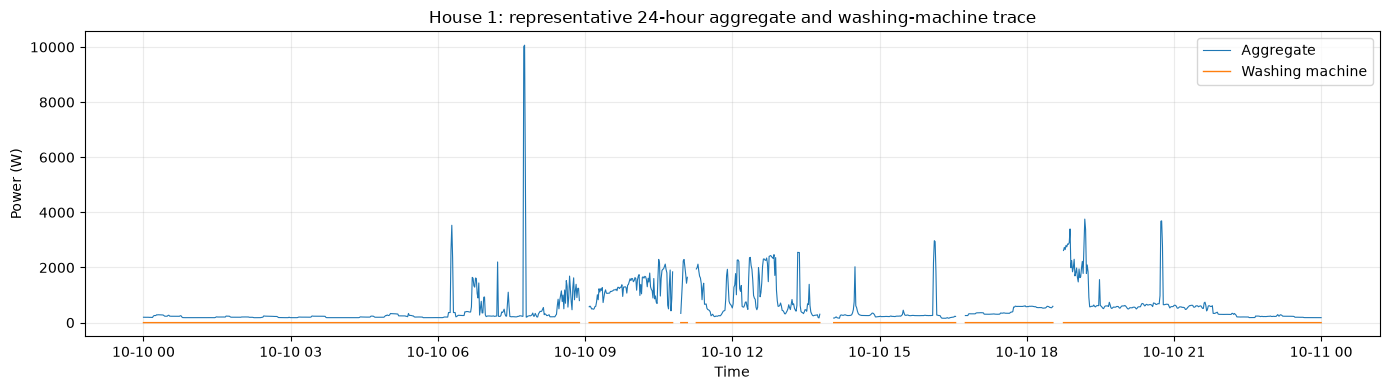

Interpretation: The aggregate signal contains the combined demand of the home, while washer activity appears as smaller intermittent sections.
The washing-machine trace is therefore difficult to infer from aggregate power alone when other appliances operate at the same time.


In [12]:
# representative 24-hour trace for one house

representative_house = 1
representative = house_data[representative_house]["data"]
representative_washer = house_data[representative_house]["washer_column"]
trace_start = representative.index.min().ceil("D")
trace = representative.loc[trace_start : trace_start + pd.Timedelta(days=1)]

figure, axis = plt.subplots(figsize=(14, 4))
axis.plot(trace.index, trace["Aggregate"], label="Aggregate", linewidth=0.8)
axis.plot(trace.index, trace[representative_washer], label="Washing machine", linewidth=1.0)
axis.set_title("House 1: representative 24-hour aggregate and washing-machine trace")
axis.set_ylabel("Power (W)")
axis.set_xlabel("Time")
axis.legend()
axis.grid(alpha=0.25)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "representative_24h_trace.png", dpi=150)
plt.show()

print("Interpretation: The aggregate signal contains the combined demand of the home, while washer activity appears as smaller intermittent sections.")
print("The washing-machine trace is therefore difficult to infer from aggregate power alone when other appliances operate at the same time.")

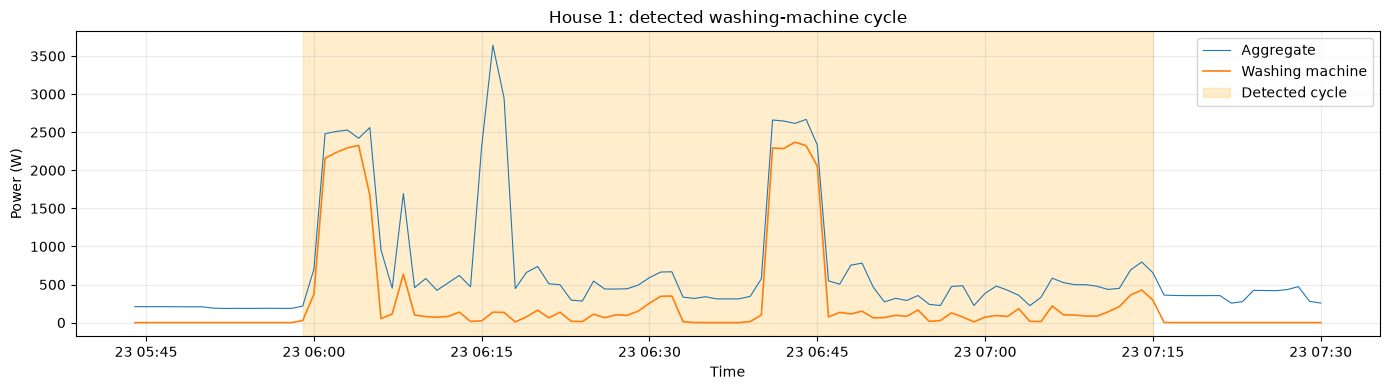

Interpretation: This cycle lasts 77 minutes and uses 496.1 Wh under the one-minute estimate.
Short low-power pauses are included because the rule merges inactive periods up to ten minutes.


In [13]:
# representative detected cycle for one house

house1_cycles = cycle_tables[1]
if house1_cycles.empty:
    raise ValueError("No House 1 cycle was detected for the configured thresholds.")
first_cycle = house1_cycles.iloc[0]
cycle_window = house_data[1]["data"].loc[
    first_cycle["start"] - pd.Timedelta(minutes=15) :
    first_cycle["end"] + pd.Timedelta(minutes=15)
]

figure, axis = plt.subplots(figsize=(14, 4))
axis.plot(cycle_window.index, cycle_window["Aggregate"], label="Aggregate", linewidth=0.8)
axis.plot(cycle_window.index, cycle_window["Appliance5"], label="Washing machine", linewidth=1.2)
axis.axvspan(first_cycle["start"], first_cycle["end"], color="orange", alpha=0.2, label="Detected cycle")
axis.set_title("House 1: detected washing-machine cycle")
axis.set_ylabel("Power (W)")
axis.set_xlabel("Time")
axis.legend()
axis.grid(alpha=0.25)
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "detected_cycle_zoom.png", dpi=150)
plt.show()

print(f"Interpretation: This cycle lasts {first_cycle['duration_minutes']:.0f} minutes and uses {first_cycle['energy_wh']:.1f} Wh under the one-minute estimate.")
print("Short low-power pauses are included because the rule merges inactive periods up to ten minutes.")

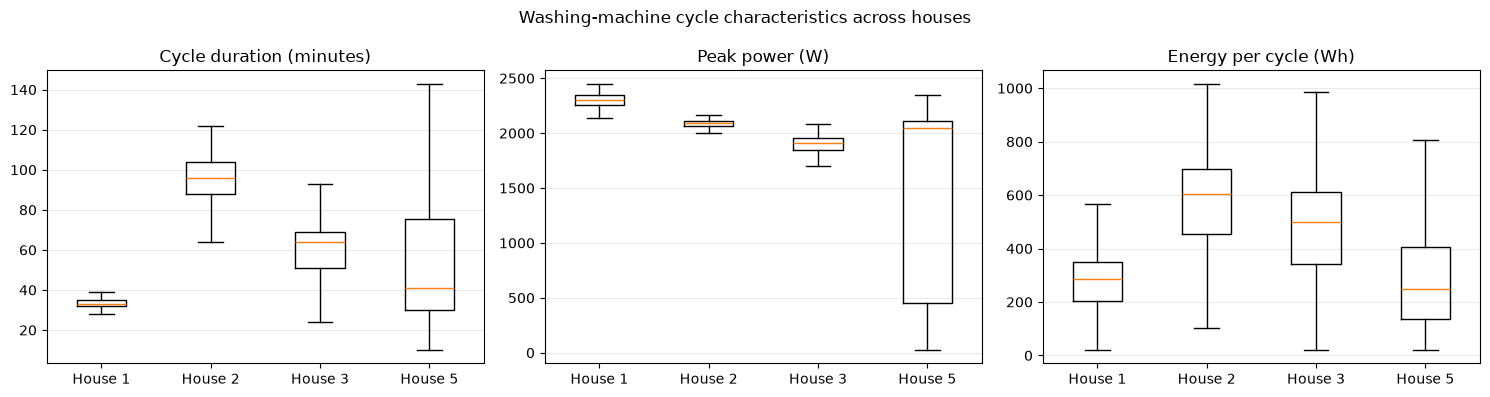

Interpretation: The distributions show whether typical washer cycles differ in duration, peak demand, or energy between households.
Differences may reflect appliance models, selected programs, household behaviour, and unequal data coverage.


In [15]:
# representative cycle characteristics across houses

comparison_metrics = [
    ("duration_minutes", "Cycle duration (minutes)"),
    ("peak_power_watts", "Peak power (W)"),
    ("energy_wh", "Energy per cycle (Wh)"),
]
figure, axes = plt.subplots(1, len(comparison_metrics), figsize=(15, 4))
for axis, (column, label) in zip(axes, comparison_metrics, strict=True):
    values = [
        cycles_all.loc[cycles_all["house"].eq(house), column].dropna()
        for house in HOUSES
    ]
    axis.boxplot(values, tick_labels=[f"House {house}" for house in HOUSES], showfliers=False)
    axis.set_title(label)
    axis.grid(axis="y", alpha=0.25)
figure.suptitle("Washing-machine cycle characteristics across houses")
figure.tight_layout()
figure.savefig(OUTPUT_DIR / "cross_house_cycle_comparison.png", dpi=150)
plt.show()

print("Interpretation: The distributions show whether typical washer cycles differ in duration, peak demand, or energy between households.")
print("Differences may reflect appliance models, selected programs, household behaviour, and unequal data coverage.")

In [ ]:
# summary of detected cycles across houses

combined_hour = hour_usage.groupby("hour", as_index=False)["cycle_count"].sum()
combined_day = day_usage.groupby("day", as_index=False)["cycle_count"].sum()
peak_hour = int(combined_hour.loc[combined_hour["cycle_count"].idxmax(), "hour"])
peak_day = combined_day.loc[combined_day["cycle_count"].idxmax(), "day"]
median_duration = cycles_all["duration_minutes"].median()
median_energy = cycles_all["energy_wh"].median()

summary = f"""
## Part 2 summary

I analysed Houses {', '.join(map(str, HOUSES))} using the official cleaned REFIT files. The washing-machine channels were {', '.join(f'House {house}: {channel}' for house, channel in HOUSES.items())}. Readings were converted to one-minute means. Rows with Issues equal to 1 were treated as unreliable, gaps up to {CONFIG['max_gap_minutes']} minutes were interpolated, and longer gaps were retained as missing.

A cycle was defined as washer power above {CONFIG['active_power_watts']:.0f} W. Pauses of up to {CONFIG['merge_pause_minutes']} minutes were merged into the same cycle. Cycles shorter than {CONFIG['minimum_cycle_minutes']} minutes or below {CONFIG['minimum_cycle_energy_wh']:.0f} Wh were discarded. Across the selected homes, the most common cycle-start hour was {peak_hour:02d}:00 and the most common start day was {peak_day}. The median detected cycle duration was {median_duration:.1f} minutes and the median cycle energy was {median_energy:.1f} Wh.

The 24-hour trace shows that washer activity is intermittent and is embedded within the larger aggregate household signal. The cycle zoom demonstrates that the threshold-and-pause rule identifies a plausible operating episode while allowing short low-power pauses. Cross-house box plots show household differences in cycle duration, peak power, and energy, so a model trained on one household should not automatically be assumed to represent another.
""".strip()
print(summary)
(OUTPUT_DIR / "part2_results_summary.md").write_text(summary + "\n", encoding="utf-8")

## Part 2 summary

I analysed Houses 1, 2, 3, 5 using the official cleaned REFIT files. The washing-machine channels were House 1: Appliance5, House 2: Appliance2, House 3: Appliance6, House 5: Appliance3. Readings were converted to one-minute means. Rows with Issues equal to 1 were treated as unreliable, gaps up to 3 minutes were interpolated, and longer gaps were retained as missing.

A cycle was defined as washer power above 20 W. Pauses of up to 10 minutes were merged into the same cycle. Cycles shorter than 10 minutes or below 20 Wh were discarded. Across the selected homes, the most common cycle-start hour was 10:00 and the most common start day was Saturday. The median detected cycle duration was 56.0 minutes and the median cycle energy was 352.2 Wh.

The 24-hour trace shows that washer activity is intermittent and is embedded within the larger aggregate household signal. The cycle zoom demonstrates that the threshold-and-pause rule identifies a plausible operating episode while

1220

: 